<a href="https://colab.research.google.com/github/erickcorrea3092/AZH_ACE_QSARMODEL/blob/main/16_AZH_NN_ANGIE_RAFA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Antecedentes

In [1]:
import sys
import numpy as np

print("Python:", sys.version)
print("NumPy:", np.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3


In [2]:
import scipy
import sklearn

print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

print("NUMPY + SCIPY + SKLEARN OK")

SciPy: 1.16.3
Scikit-learn: 1.6.1
NUMPY + SCIPY + SKLEARN OK


In [3]:
try:
    import umap
    print("UMAP:", umap.__version__)
    print("UMAP OK")
except Exception as e:
    print("ERROR UMAP:")
    print(type(e).__name__, e)

UMAP: 0.5.12
UMAP OK


In [4]:
# Instalación limpia y silenciosa sin saturar el navegador
!pip install -q torch rdkit transformers molplotly plotly seaborn xgboost

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 123.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 132.0 MB/s eta 0:00:00


In [5]:
import plotly.io as pio

# Utiliza el renderer nativo e aislado de Colab
pio.renderers.default = "colab"

In [6]:
# Exportamos la librerías
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
# with tqdm.notebook.tqdm(total=total) as pbar:
#     with io.capture_output() as captured:
#       pbar.update(0)
#       !pip install torch
#       !pip install rdkit
#       !pip install transformers
#       !pip install molplotly rdkit plotly pandas dash==3.2.0
#       !pip install seaborn
#       !pip install xgboost
#       pbar.update(100)

## Imports

In [7]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      import numpy as np
      import pandas as pd
      from rdkit import Chem
      from rdkit.Chem import AllChem
      from rdkit.ML.Descriptors import MoleculeDescriptors
      from rdkit.Chem import Descriptors
      from rdkit import DataStructs
      from rdkit.Chem import rdMolDescriptors
      from rdkit.Chem.Descriptors import MolWt
      from rdkit.Chem.Descriptors import MolLogP
      from rdkit.Chem.Descriptors import NumHAcceptors
      from rdkit.Chem.Descriptors import NumHDonors
      from rdkit.Chem.Descriptors import MolLogP
      from rdkit.Chem import Lipinski
      from rdkit.Chem import QED
      from rdkit.Chem import MolSurf
      from IPython.display import SVG # to use Scalar Vector Graphics (SVG) not bitmaps, for cleaner lines
      from rdkit.Chem import Draw # to draw molecules
      from rdkit.Chem.Draw import IPythonConsole # to draw inline in iPython
      from rdkit.Chem import rdDepictor  # to generate 2D depictions of molecules
      from rdkit.Chem.Draw import rdMolDraw2D # to draw 2D molecules using vectors
      import matplotlib.pyplot as plt
      import seaborn as sns
      import molplotly
      import plotly.express as px
      import sklearn
      from sklearn.ensemble import RandomForestClassifier
      from sklearn.ensemble import RandomForestRegressor
      from sklearn import metrics
      from sklearn.metrics import confusion_matrix, classification_report
      from sklearn.model_selection import KFold, StratifiedShuffleSplit
      from sklearn import metrics
      from sklearn.pipeline import Pipeline
      from sklearn.ensemble import RandomForestClassifier
      from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer
      from sklearn.ensemble import GradientBoostingRegressor
      import xgboost as xgb
      from transformers import AutoTokenizer, AutoModelForMaskedLM
      from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit
      import torch
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [8]:

# import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import KFold, StratifiedShuffleSplit
from sklearn.svm import SVR
from sklearn.svm import NuSVR
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer
from sklearn.feature_selection import (SelectFromModel, SelectKBest, VarianceThreshold)
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import random

In [9]:

# 2. Funión para generar embeddings
def get_molecule_embedding(smiles, model, tokenizer):
    inputs = tokenizer(smiles, return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
    with torch.no_grad():
        outputs = model(**inputs, output_hidden_states=True)
        last_hidden_state = outputs.hidden_states[-1]
        #return last_hidden_state[:,0,:].squeeze().cpu().numpy() #get the first row of embedding (classification token)
        return last_hidden_state.mean(dim=1).squeeze().cpu().numpy() #average values


# Globales

In [10]:
# Banderitas par activar operaciones
e = True #activa el cálculo de embedding
val = False # activa el proceso de validación cruzada
grid_test = False #Activa el proceso de mejora de hiperparámetros
grid_cv = False #Activa el proceso de mejora de hiperparámetros
# 1 semilla para cosas random
RANDOM_STATE = 5712492

# 2 Minima varianza a conservar en las features
MIN_VARIANCE = 0

# 3 Separación
N_BINS=5 ##discretizer
N_SPLITS=10 ##splitter
TEST_SIZE=21/70 ##splitter


In [11]:
# Fijar semillas para reproducibilidad
def set_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # Si usas GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)  # Establecer semilla global

# Datos


## Datos

In [12]:
# descargamos data
! gdown --id 1HTl5qJu_IEPKqWRQ-28NG0mZZVRO_H9b
#! gdown --id 1R3EXQRLLQKYvwbQPej6hyeWGLRZ-UTMw

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1HTl5qJu_IEPKqWRQ-28NG0mZZVRO_H9b
From (redirected): https://drive.google.com/uc?id=1HTl5qJu_IEPKqWRQ-28NG0mZZVRO_H9b&confirm=t&uuid=67339ce4-a6e3-4fc1-9d95-6edcfac06dc5
To: /content/AZH_descriptors_1.csv
100% 161M/161M [00:01<00:00, 81.6MB/s]


In [13]:
data = pd.read_csv("AZH_descriptors_1.csv")
# data.head()

/tmp/ipykernel_1372/441936392.py:1: DtypeWarning:

Columns (154,155,156,157,163,164,165,166,172,173,174,175,181,182,183,184,190,191,192,193,199,200,201,202,208,209,210,211,217,218,219,220,226,227,228,229,235,236,237,238,244,245,246,247,248,249,250,251,252,253,254,255,256,356,357,358,359,360,361,362,363,364,370,371,372,373,379,380,381,382,388,389,390,391,397,398,399,400,406,407,408,409,415,416,417,418,424,425,426,427,433,434,435,436,442,443,444,445,451,452,453,454,460,461,462,463,464,465,466,467,468,469,470,471,476,477,478,479,484,485,486,487,492,493,494,495,500,501,502,503,508,509,510,511,516,517,518,519,524,525,526,527,532,533,534,535,540,541,542,543,548,549,550,551,556,557,558,559,560,561,562,563,564,565,566,567,572,573,574,575,580,581,582,583,588,589,590,591,596,597,598,599,604,605,606,607,612,613,614,615,620,621,622,623,628,629,630,631,636,637,638,639,644,645,646,647,652,653,654,655,656,657,795,796,843,844,845,846,847,859,860,861,862,863,1072,1075,1080,1151,1154,1159,1256,1259,1261

In [14]:
smiles_stand = data["SMILES"]

# Embeddings

In [15]:
if e==True:
  from tqdm import tqdm
  # 1. Cargar modelos y tokenizador
  tokenizer = AutoTokenizer.from_pretrained("DeepChem/ChemBERTa-77M-MLM")
  model = AutoModelForMaskedLM.from_pretrained("DeepChem/ChemBERTa-77M-MLM")
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  model = model.to(device)
  # 3. Procesar todos los SMILES (con barra de progreso)
  embeddings = []
  failed_smiles = []
  for smile in tqdm(smiles_stand, desc="Generando embeddings"):
    try:
        if pd.isna(smile) or not smile:  # Pula valores nulos/vazios
            continue
        emb = get_molecule_embedding(smile, model, tokenizer)
        embeddings.append(emb)
    except Exception as e:
        failed_smiles.append(smile)
        continue




config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.96k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.26k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/60 [00:00<?, ?it/s]

Generando embeddings:   0%|          | 0/5254 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 13.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Generando embeddings: 100%|██████████| 5254/5254 [00:57<00:00, 90.97it/s] 


In [16]:
# 4. Converter para DataFrame
df_embeddings = pd.DataFrame(embeddings)
#df_embeddings['SMILES'] = [s for s in smiles_ache_stand if s not in failed_smiles]
#df_embeddings['Activity'] = data['Activity']
#df_embeddings['fraction'] = df_data['fraction']
print(f"\nEmbeddings generados: {len(embeddings)}")
print(f"SMILES fallidos: {len(failed_smiles)}")
print(f"Shape dos embeddings: {df_embeddings.shape}")
df_data = df_embeddings
df_data['Activity'] = data['pChEMBL Value']
#df_data['fraction'] = df_data['fraction']
# df_data


Embeddings generados: 5254
SMILES fallidos: 0
Shape dos embeddings: (5254, 384)


In [17]:
df_x = df_embeddings.iloc[:, :-1]  # Todas as linhas, todas as colunas exceto a última
df_y = df_embeddings.iloc[:, -1]   # Todas as linhas, apenas a última coluna (target)

# Definimos xplor

In [18]:
excel = True
SMILES_LIST = False
comercial = True

In [19]:
smiles_dict = {'Manu021':'CN1C[C@H]2N(CC(C3=CC=C(OC)C=C3)=O)C[C@@H]1C2',
               'Manu022':'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6=NC(C=CC(Br)=C7)=C7S6)C(CS5)=O)[C@@H](C4)C3)C=C21)=O',
               #'Manu023' :'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@H]4CN(C5N(C6=NC(C=CC(Br)=C7)=C7S6)C(CS5)=O)[C@H](C4)C3)C=C21)=O',
               #'Manu024': 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(Br)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               #'Manu024': 'O=C(C1=CC(F)=C(N2[C@H]3CN(C4N(C5=NC(C=CC(Br)=C6)=C6S5)C(CS4)=O)[C@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               #'Manu025' : 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OCC)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               #'Manu026' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=C(F)C=CC=C6)=N3',
               #'Manu027' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=CC=C(F)C=C6)=N3',
               #'Manu028' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=C(C(F)(F)F)C=CC=C6)=N3',
               #'Manu029' : 'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6=NC(C=CC(NC(C)=O)=C7)=C7S6)C(CS5)=O)[C@@H](C4)C3)C=C21)=O',
               #'Manu030' : 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OC)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'ecp_01':'O=C1C2=C(C=C(F)C(N3CCN(C)CC3)=C2)C=NO1'}
comercial_drugs = {#______penicilinas________________________
               'penicilna G' : 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)CC3=CC=CC=C3)C(=O)O)C',
               'oxaciline': 'CC1=C(C(=NO1)C2=CC=CC=C2)C(=O)N[C@H]3[C@@H]4N(C3=O)[C@H](C(S4)(C)C)C(=O)O',
               }


In [20]:
xplor = pd.DataFrame()
if excel is True:
  #convierte smiles_dict en un dataframe
  #____DEBES DEFINIR OD Y NOMBRE DEL ARCHIVO
  # !gdown --id 1X_-Wkub7b-89rrJ8nN2FxH1f9joorr_d #IMPORTANTE
  # excel = pd.read_excel("NAPRONA_CURATED.xlsx") #IMPORTANTE
  # El archivo EXCEL SOLO DEBE TENER DOS columnas: 'SMILES' y 'Cmpd'
  #______________________________________________
  # ! gdown --id 1IGs5emsGuqycnLA47j7YgwWbyb6SWnSL
  # excel = pd.read_excel("kurt_xplor1_.xlsx")
  #_______________________________________________
# }  ! gdown --id 1Z5k3LY4lD8urfTUmGIl3HeEwX6hQaM6l
#   excel = pd.read_excel("valid_smiles3.xlsx")
  #________________________________________________
  # ! gdown --id 1_vE6EPXJYAiPR1g6kBl2uE5u_-aJ1oft
  # excel = pd.read_excel("drugs.xlsx")
  #______________________________________

  ! gdown --id 1xJlMEy_h5xkBKeVmC9lWuYrEPJx_hFxx
  excel = pd.read_excel("L9_SMILES.xlsx")
  #______________________________________________

  excel['G'] = 'xplor'
  # excel['Cluster_number'] = len(set(cluster_id))+1
  xplor = pd.concat([xplor, excel], ignore_index=True)
  print('Un archivo excel se adicionó a xplor')
else:
    print('NO se proceso EXCEL para adicionar a xplor')


if SMILES_LIST is True:
  #convierte smiles_dict en un dataframe
  sl = pd.DataFrame(list(smiles_dict.items()), columns=['Cmpd', 'SMILES'])
  sl['G'] = 'xplor'
  # sl['Cluster_number'] = len(set(cluster_id))+1
  xplor = pd.concat([xplor, sl], ignore_index=True)
  print('Un diccionario con SMILES se adicionó a xplor')
else:
  print('NO se proceso el DICCIONARIO para adicionar a xplor')

if comercial is True:
  #convierte comercial_drugs en un dataframe
  com_drugs = pd.DataFrame(list(comercial_drugs.items()), columns=['Cmpd', 'SMILES'])
  com_drugs['G'] = 'comercial'
  # com_drugs['Cluster_number'] = len(set(cluster_id))+2
  xplor = pd.concat([xplor, com_drugs], ignore_index=True)
  print('Los fármacos comerciales se tomarán en cuenta')
else:
  print('NO se tomarán en cuenta los fármacos comerciales')

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1xJlMEy_h5xkBKeVmC9lWuYrEPJx_hFxx
To: /content/L9_SMILES.xlsx
100% 31.1k/31.1k [00:00<00:00, 68.0MB/s]
Un archivo excel se adicionó a xplor
NO se proceso el DICCIONARIO para adicionar a xplor
Los fármacos comerciales se tomarán en cuenta


In [21]:
smiles_test = xplor['SMILES']

In [22]:
e_test = True

In [23]:
if e_test==True:
  from tqdm import tqdm
  # 1. Cargar modelos y tokenizador
  tokenizer = AutoTokenizer.from_pretrained("DeepChem/ChemBERTa-77M-MLM")
  model = AutoModelForMaskedLM.from_pretrained("DeepChem/ChemBERTa-77M-MLM")
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  model = model.to(device)
  # 3. Procesar todos los SMILES (con barra de progreso)
  embeddings_xplor = []
  failed_smiles_xplor = []
  for smile in tqdm(smiles_test, desc="Generando embeddings"):
    try:
        if pd.isna(smile) or not smile:  # Pula valores nulos/vazios
            continue
        emb_tst = get_molecule_embedding(smile, model, tokenizer)
        embeddings_xplor.append(emb_tst)
    except Exception as e:
        failed_smiles_xplor.append(smile)
        continue

Loading weights:   0%|          | 0/60 [00:00<?, ?it/s]

Generando embeddings: 100%|██████████| 1444/1444 [00:16<00:00, 85.58it/s]


In [24]:
# 4. Converter para DataFrame
df_embeddings_xplor = pd.DataFrame(embeddings_xplor)
#df_embeddings['SMILES'] = [s for s in smiles_ache_stand if s not in failed_smiles]
#df_embeddings['Activity'] = data['Activity']
#df_embeddings['fraction'] = df_data['fraction']
print(f"\nEmbeddings gerados: {len(embeddings_xplor)}")
print(f"SMILES fallidos: {len(failed_smiles_xplor)}")
print(f"Shape dos embeddings: {df_embeddings_xplor.shape}")


Embeddings gerados: 1442
SMILES fallidos: 0
Shape dos embeddings: (1442, 384)


#Separación

In [25]:
# dividimos train test con stratified
discretizer = sklearn.preprocessing.KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="uniform")
splitter = StratifiedShuffleSplit(n_splits=N_SPLITS, test_size=0.4, random_state=RANDOM_STATE)
# Reshape y_discrete to be a 2D array (n_samples, 1)
y_discrete = discretizer.fit_transform(df_y.values.reshape(-1, 1))
split, split_test = next(splitter.split(df_x.values, y_discrete))
fractions = ["train" if i in split else "test" for i in range(df_data.shape[0])]
df_data = df_data.assign(fraction=fractions)
#df_data

In [26]:
str(list(data.columns))

"['QED', 'MolWt', 'LogP', 'HAC', 'RB', 'TPSA', 'HBA', 'HDB', 'Activity', 'SMILES', 'Structure', 'Molecule ChEMBL ID', 'pChEMBL Value', 'Molecule Name', 'Cluster_number', 'ABC', 'ABCGG', 'nAcid', 'nBase', 'SpAbs_A', 'SpMax_A', 'SpDiam_A', 'SpAD_A', 'SpMAD_A', 'LogEE_A', 'VE1_A', 'VE2_A', 'VE3_A', 'VR1_A', 'VR2_A', 'VR3_A', 'nAromAtom', 'nAromBond', 'nAtom', 'nHeavyAtom', 'nSpiro', 'nBridgehead', 'nHetero', 'nH', 'nB', 'nC', 'nN', 'nO', 'nS', 'nP', 'nF', 'nCl', 'nBr', 'nI', 'nX', 'ATS0dv', 'ATS1dv', 'ATS2dv', 'ATS3dv', 'ATS4dv', 'ATS5dv', 'ATS6dv', 'ATS7dv', 'ATS8dv', 'ATS0d', 'ATS1d', 'ATS2d', 'ATS3d', 'ATS4d', 'ATS5d', 'ATS6d', 'ATS7d', 'ATS8d', 'ATS0s', 'ATS1s', 'ATS2s', 'ATS3s', 'ATS4s', 'ATS5s', 'ATS6s', 'ATS7s', 'ATS8s', 'ATS0Z', 'ATS1Z', 'ATS2Z', 'ATS3Z', 'ATS4Z', 'ATS5Z', 'ATS6Z', 'ATS7Z', 'ATS8Z', 'ATS0m', 'ATS1m', 'ATS2m', 'ATS3m', 'ATS4m', 'ATS5m', 'ATS6m', 'ATS7m', 'ATS8m', 'ATS0v', 'ATS1v', 'ATS2v', 'ATS3v', 'ATS4v', 'ATS5v', 'ATS6v', 'ATS7v', 'ATS8v', 'ATS0se', 'ATS1se', 'A

In [27]:
df_data_2 = data.iloc[:, :13].copy()
df_data_2 = df_data_2.drop('Activity', axis=1)
df_data_2 = pd.concat([df_data_2, df_data], axis=1)
df_data_2

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,SMILES,Structure,...,376,377,378,379,380,381,382,383,Activity,fraction
0,0.197668,578.805,6.51442,43,11,73.39,6,2,Cc1c(N2CCN(C)CC2)nc2ccccc2c1C(=O)NCCCCCCCNc1c2...,<rdkit.Chem.rdchem.Mol object at 0x7a28d1c50970>,...,0.000112,0.068866,0.065302,-0.242486,0.084260,-0.006746,0.003815,-0.035065,8.39,test
1,0.385319,358.442,3.10360,26,10,89.32,6,2,O=[N+]([O-])OCCCNCCCNc1c2c(nc3ccccc13)CCCC2,<rdkit.Chem.rdchem.Mol object at 0x7a28d16df760>,...,-0.012957,0.188648,0.046466,-0.221952,0.150476,-0.073026,-0.024125,-0.026748,8.19,train
2,0.653235,310.485,5.80432,23,7,24.92,2,1,CCCCCCCNc1c2c(nc3cc(C)ccc13)CCCC2,<rdkit.Chem.rdchem.Mol object at 0x7a28d1c505f0>,...,0.043141,0.071913,0.024576,-0.241092,0.102036,0.008262,0.148127,-0.064528,6.89,test
3,0.038102,638.884,7.00050,48,14,104.90,6,5,Nc1ccc2c(c1)c(-c1ccccc1)[n+](CCCNCCCNCCCNc1c3c...,<rdkit.Chem.rdchem.Mol object at 0x7a28d1c03290>,...,-0.021829,0.156692,0.081466,-0.234945,-0.076260,-0.140418,-0.021546,-0.157315,8.81,test
4,0.154825,595.618,10.01430,42,10,49.84,4,2,Clc1ccc2c(NCCCCCCCNc3c4c(nc5cc(Cl)ccc35)-c3ccc...,<rdkit.Chem.rdchem.Mol object at 0x7a28d171e340>,...,0.016893,0.007669,0.113280,-0.193557,0.054065,0.002877,0.063200,-0.066707,7.92,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5249,0.346302,318.325,2.17400,23,7,93.06,6,2,COC/C(C=O)=C\CCC1=CC(c2cc(O)ccc2O)OC1=O,<rdkit.Chem.rdchem.Mol object at 0x7a28d1c52420>,...,0.071550,0.025006,0.018732,-0.058290,0.057226,0.178905,-0.075585,-0.133069,5.07,train
5250,0.564648,348.446,3.70850,26,5,62.82,3,1,CC(C)=CCCC(C)CC=c1ccc(=O)c2[nH]c3cccc(=O)c3nc12,<rdkit.Chem.rdchem.Mol object at 0x7a28d1c51cb0>,...,-0.017953,-0.018065,0.174401,-0.235784,-0.007400,0.184397,-0.025613,-0.079373,5.58,train
5251,0.497332,124.163,0.51970,9,1,13.11,1,0,COc1cccc[n+]1C,<rdkit.Chem.rdchem.Mol object at 0x7a28d1c50a50>,...,0.093351,-0.041914,0.190792,-0.345870,0.062948,0.164802,0.270752,-0.125706,4.34,train
5252,0.131806,686.982,7.59140,50,21,83.14,6,2,O=C(CCCCCCC(=O)NCCCCCCN1CC[C@H]2COc3ccccc3[C@H...,<rdkit.Chem.rdchem.Mol object at 0x7a28d1c50510>,...,-0.119636,0.152409,0.065456,-0.294846,0.141804,0.129685,0.027173,-0.040803,5.01,test


<Figure size 1000x800 with 0 Axes>

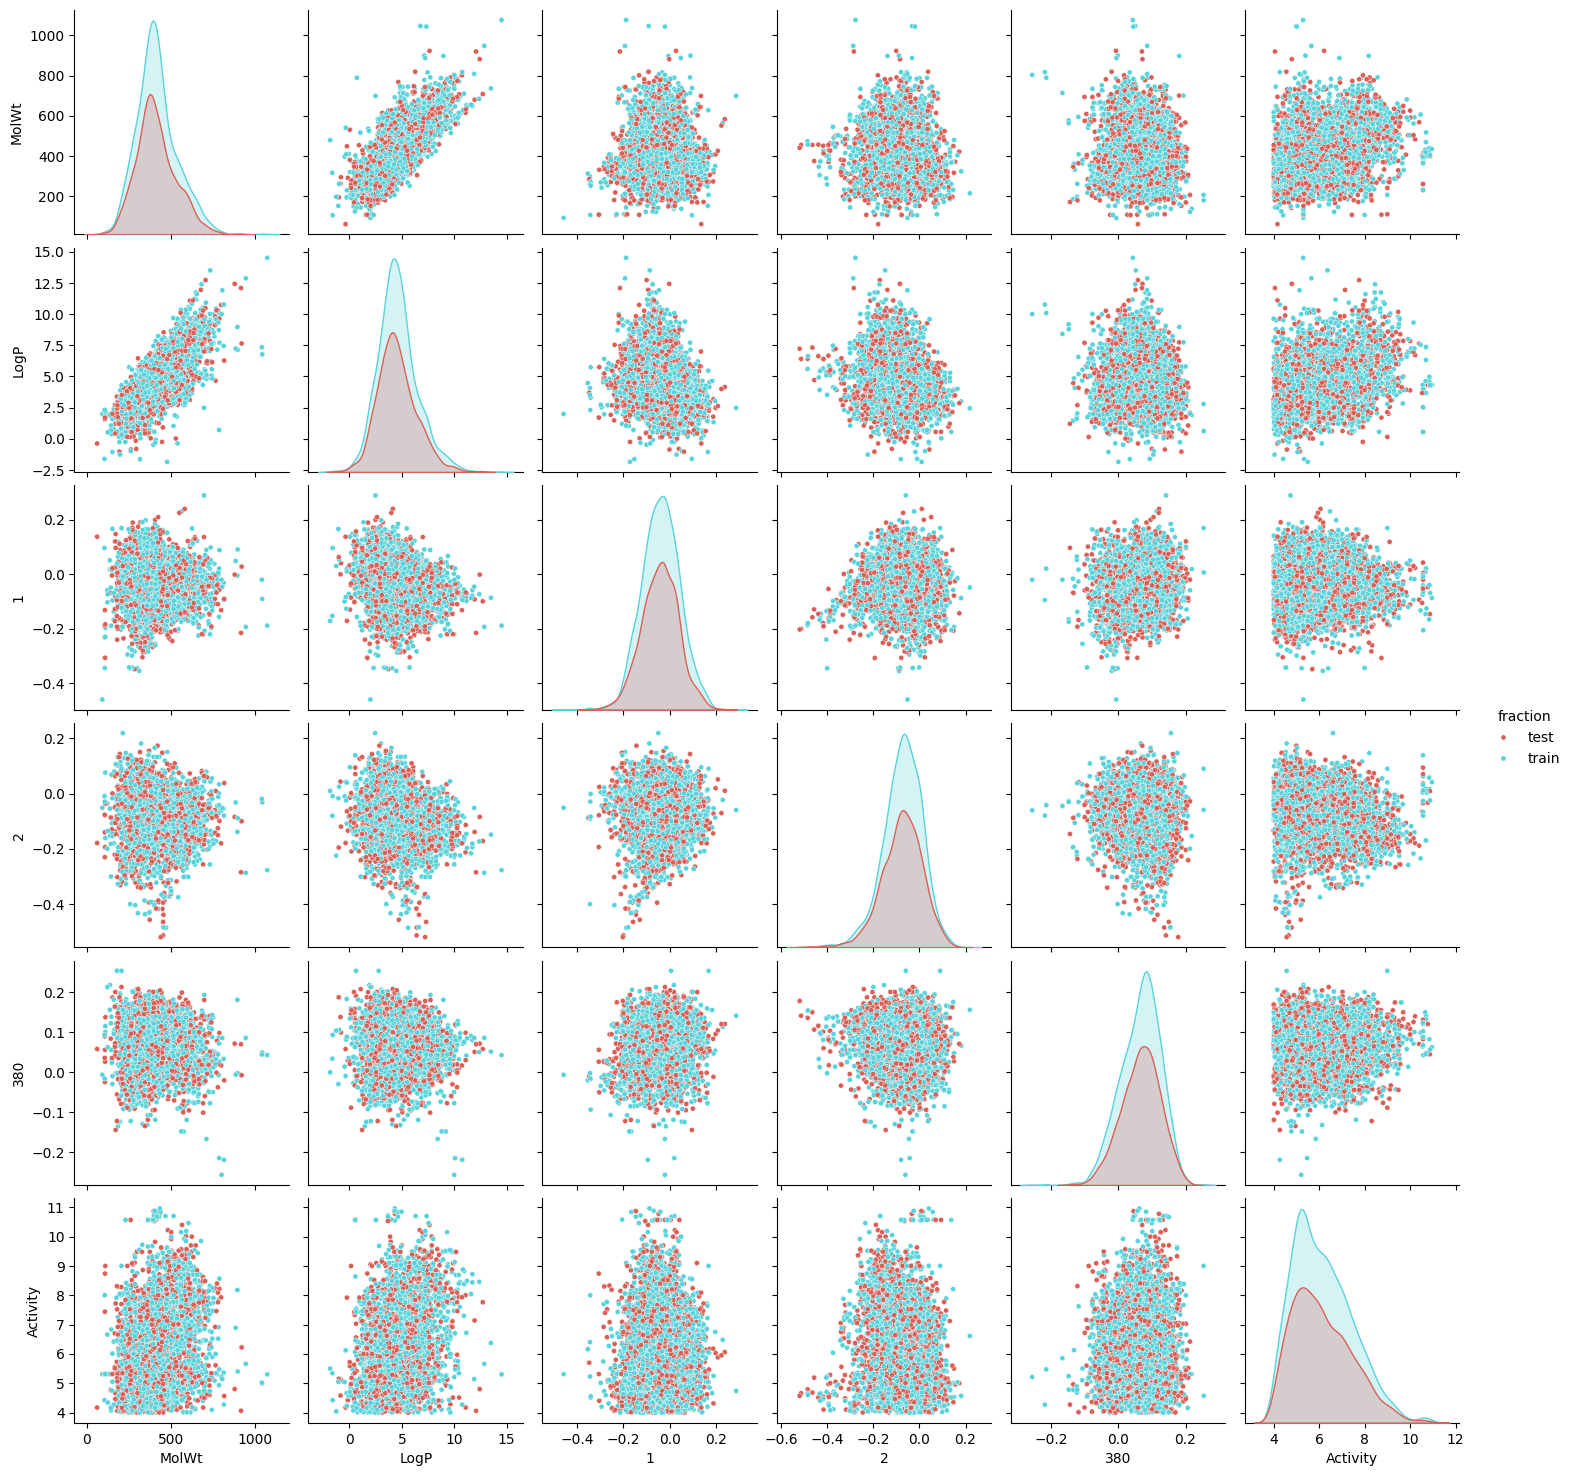

In [28]:
# prompt: repite la matriz de dispersión con plt

fig1 = plt.figure(figsize=(10, 8))  # Adjust figure size as needed
sns.pairplot(data=df_data_2,
             vars=['MolWt','LogP',#'TPSA','RB', 'QED', 'HBA', 'HDB',
                   1,2,380,
                   #120,382,
                   'Activity'],
             hue="fraction", # Use the original string column for hue
             palette="hls", # You can change the color palette
             diag_kind="kde", # Use kernel density estimate for diagonal plots
             plot_kws={'s': 14, #'edgecolor': 'black', 'linewidth': 1
                       }) # Adjust marker size and outline

#plt.suptitle('Matriz de dispersión del Espacio Químico, Descriptores Individuales', y=1.02) # Add a title to the overall plot
#plt.show()


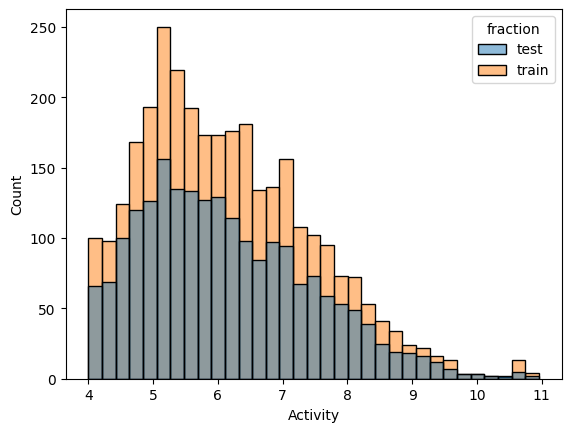

In [29]:
# prompt: con seaborn has un histograma de activity donde se muestre el test y train de fraction

import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=df_data, x="Activity", hue="fraction")
plt.show()


In [30]:
# sacamos los vectores (x, y) de interés
x_train = df_data[df_data["fraction"] == "train"]
x_train_ = df_data_2[df_data_2["fraction"] == "train"]
x_train.drop('fraction', axis=1, inplace=True)
x_train.drop('Activity', axis=1, inplace=True)

x_train = x_train.values
#________________________________________
y_train = df_data[df_data["fraction"] == "train"]
y_train = y_train['Activity']
y_train = y_train.values

#_________________________________
#_________________________________
x_test = df_data[df_data["fraction"] == "test"]
x_test_ = df_data_2[df_data_2["fraction"] == "test"]
x_test.drop('fraction', axis=1, inplace=True)
x_test.drop('Activity', axis=1, inplace=True)
x_test = x_test.values
#________________________________________
y_test = df_data[df_data["fraction"] == "test"]
y_test = y_test['Activity']
#y_test = y_test
y_test = y_test.values


y_train = np.reshape(y_train, -1)
y_test = np.reshape(y_test, -1)

/tmp/ipykernel_1372/1074368734.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_1372/1074368734.py:5: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_1372/1074368734.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_1372/1074368734.py:18: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydat

In [31]:
x_train = x_train.astype(float)
y_train = y_train.astype(float)
x_test = x_test.astype(float)
y_test = y_test.astype(float)

## tensores y Dataloaders

In [32]:
# pasamos datos a torch
x_train = torch.from_numpy(x_train).float()
y_train = torch.from_numpy(y_train).float().reshape(-1, 1)
x_test = torch.from_numpy(x_test).float()
y_test = torch.from_numpy(y_test).float().reshape(-1, 1)

In [33]:
# Crear DataLoaders para entrenamiento y validación
batch_size = 49
train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# Red Neuronal

In [34]:
# Definir tamaño de entrada (8 para California Housing)
input_size = x_train.shape[1]
input_size

384

In [35]:
class RegressionNet(nn.Module):
    def __init__(self, input_size, hidden_size=600, dropout_rate=0.1): # hidden size 600 es el bueno
        super(RegressionNet, self).__init__()
        self.model = nn.Sequential(
            #1er capa
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            #2a capa
            nn.Linear(hidden_size, (24)),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            #Capa de regresión
            nn.Linear(24, 12),  # Salida para regresión
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            #Capa de regresión
            nn.Linear(12, 1)  # Salida para regresión


        )

    def forward(self, x):
        return self.model(x)

In [36]:
class EarlyStopping:
    def __init__(self, patience=10, delta=0.5):
        self.patience = patience  # Número de épocas sin mejora antes de detener
        self.delta = delta  # Mejora mínima requerida
        self.best_loss = float('inf')
        self.epochs_no_improve = 0
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.delta:
            self.best_loss = val_loss
            self.epochs_no_improve = 0
            self.best_model_state = model.state_dict()  # Guardar el mejor modelo
        else:
            self.epochs_no_improve += 1
            if self.epochs_no_improve >= self.patience:
                self.early_stop = True

# Entrenamiento

In [37]:
ear_stop = False

### Entrenamiento

In [38]:
# Hiperparámetros
learning_rate = 0.001
num_epochs = 400  # Puede ser mayor, ya que early stopping detendrá antes si es necesario
patience = 500  # Número de épocas sin mejora
# Inicializar modelo, criterio y optimizador
model = RegressionNet(input_size)
criterion = nn.MSELoss()
# optimizer = optim.Adam(model.parameters(), lr=learning_rate)
optimizer = optim.RMSprop(model.parameters(), lr=learning_rate)
#optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [39]:
if ear_stop==True:
  model.train()
  early_stopping = EarlyStopping(patience=patience, delta=0.001)
  # Listas para almacenar pérdidas
  train_losses = []
  val_losses = []
# Entrenamiento
  for epoch in range(num_epochs):
    #Entrenamiento
      epoch_train_loss = 0
      for X_batch, y_batch in train_loader:
          optimizer.zero_grad()
          outputs = model(X_batch)
          loss = criterion(outputs, y_batch)
          loss.backward()
          optimizer.step()
          epoch_train_loss += loss.item() * X_batch.size(0)
      epoch_train_loss /= len(train_loader.dataset)
      train_losses.append(epoch_train_loss)
    # Evaluación en validación
      model.eval()
      val_loss = 0
      with torch.no_grad():
          for X_batch, y_batch in val_loader:
              outputs = model(X_batch)
              val_loss += criterion(outputs, y_batch).item() * X_batch.size(0)
      val_loss /= len(val_loader.dataset)
      val_losses.append(val_loss)
      # Early stopping
      early_stopping(val_loss, model)
      if early_stopping.early_stop:
          print(f'Early stopping en época {epoch + 1}, mejor pérdida de validación: {early_stopping.best_loss:.4f}')
          break
      if (epoch + 1) % 20 == 0:
          print(f'Epoch [{epoch + 1}/{num_epochs}], Train Loss: {epoch_train_loss:.4f}, Val Loss: {val_loss:.4f}')
      #train_losses.append(loss.item())


  # Cargar el mejor modelo
  model.load_state_dict(early_stopping.best_model_state)


In [40]:
if ear_stop ==False:
  # Listas para almacenar pérdidas
  model.train()
  train_losses = []
  val_losses = []
  # Entrenamiento
  for epoch in range(num_epochs):
    for X_batch, y_batch in train_loader:
      optimizer.zero_grad()
      outputs = model(X_batch)
      loss = criterion(outputs, y_batch)
      loss.backward()
      optimizer.step()
    if (epoch + 1) % 20 == 0:
      print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')
    train_losses.append(loss.item())

Epoch [20/400], Loss: 0.6426
Epoch [40/400], Loss: 0.5161
Epoch [60/400], Loss: 0.5587
Epoch [80/400], Loss: 0.3376
Epoch [100/400], Loss: 0.3572
Epoch [120/400], Loss: 0.1899
Epoch [140/400], Loss: 0.4683
Epoch [160/400], Loss: 0.9176
Epoch [180/400], Loss: 0.1537
Epoch [200/400], Loss: 0.1042
Epoch [220/400], Loss: 0.0774
Epoch [240/400], Loss: 0.1257
Epoch [260/400], Loss: 0.0493
Epoch [280/400], Loss: 0.0621
Epoch [300/400], Loss: 0.0581
Epoch [320/400], Loss: 0.0616
Epoch [340/400], Loss: 0.0601
Epoch [360/400], Loss: 0.0589
Epoch [380/400], Loss: 0.0944
Epoch [400/400], Loss: 0.0468


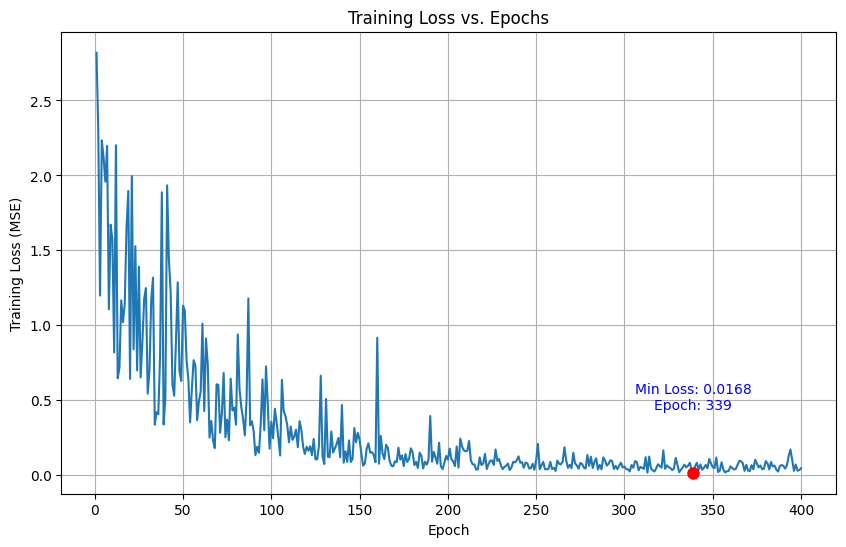

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Loss (MSE)")
plt.title("Training Loss vs. Epochs")
plt.grid(True)

# Calculate min_loss and min_loss_epoch if train_losses is not empty
if train_losses:
    min_loss = min(train_losses)
    min_loss_epoch = train_losses.index(min_loss) + 1

    # Add text annotation for min_loss and min_loss_epoch
    plt.text(min_loss_epoch, min_loss+0.5, f'Min Loss: {min_loss:.4f}\nEpoch: {min_loss_epoch}',
             fontsize=10, color='blue', ha='center', va='center') # Changed color and va for better visibility

    # Add a marker at the min_loss_epoch
    plt.plot(min_loss_epoch, min_loss, 'o', color='red', markersize=8, label=f'Min Loss at Epoch {min_loss_epoch}') # Add a red circle marker


plt.show()

In [42]:
if ear_stop==True:
  # Load the best model state dictionary
  best_model = RegressionNet(input_size)  # Create a new instance of the model
  best_model.load_state_dict(early_stopping.best_model_state)# por si se aplica early stopping esta linea selecciona el mejor modelo
  # best_model.eval() # Set the model to evaluation mode

In [43]:
if ear_stop==True:
  best_model.eval()
else:
  model.eval()

In [44]:
#torch.save(early_stopping.best_model_state, 'california_model.pth')

# Evaluación

## Bondad de ajuste

The R-squared score between y_train and yg is: 0.9658337831497192


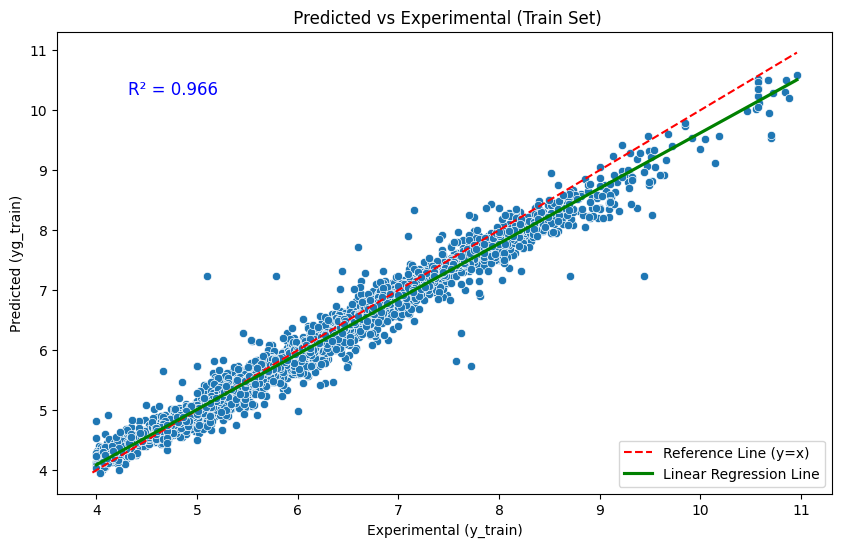

In [45]:

preds = model(x_train)
df_preds = pd.DataFrame(y_train)
df_preds = df_preds.rename(columns={0: 'y_train'})
df_preds = df_preds.assign(yg=preds.detach().numpy())
from sklearn.metrics import r2_score

# Calculate the R-squared score between y_train and yg
r2_l = r2_score(df_preds['y_train'], df_preds['yg'])
print(f"The R-squared score between y_train and yg is: {r2_l}")

p = pd.DataFrame(y_train)
# df_preds = pd.DataFrame(y_train)
p = p.rename(columns={0: 'y_train'})
p = p.assign(yg_train=preds.detach().numpy())



plt.figure(figsize=(10, 6))
sns.scatterplot(x='y_train', y='yg_train', data=p)

# Add a reference line (y=x)
max_val = max(p['y_train'].max(), p['yg_train'].max())
min_val = min(p['y_train'].min(), p['yg_train'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Reference Line (y=x)')

# Add a simple linear regression line
sns.regplot(x='y_train', y='yg_train', data=p, scatter=False, color='green', label='Linear Regression Line')

# Add the R-squared value to the plot
plt.text(min_val + (max_val - min_val) * 0.05, max_val - (max_val - min_val) * 0.1, f'R² = {r2_l:.3f}', fontsize=12, color='blue')


plt.xlabel("Experimental (y_train)")
plt.ylabel("Predicted (yg_train)")
plt.title(" Predicted vs Experimental (Train Set)")
plt.legend()
plt.grid(False)
plt.show()

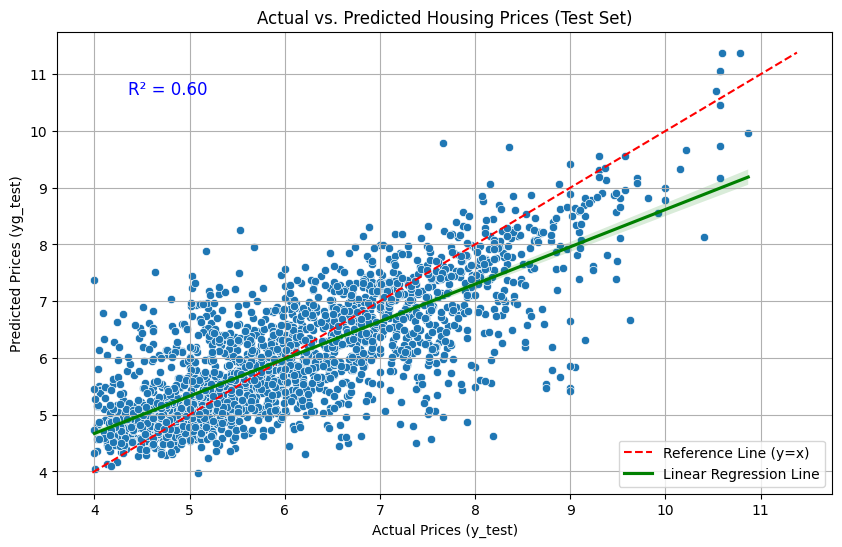

In [46]:
# Evaluación en el conjunto externo

with torch.no_grad():
    y_pred = model(x_test).numpy()
    y_true = y_test.numpy()

#Calculamos índices
mse_test = mean_squared_error(y_true, y_pred)
r2_test = r2_score(y_true, y_pred)

#Guardamos los datos en predicted_test que es un df
predicted_test = pd.DataFrame(y_true, columns=['y_test']) # Initialize with y_true
predicted_test = predicted_test.assign(yg_test=y_pred) # Assign y_pred


#Generamos la gráfica
plt.figure(figsize=(10, 6))
sns.scatterplot(x='y_test', y='yg_test', data=predicted_test)

# Add a reference line (y=x)
max_val = max(predicted_test['y_test'].max(), predicted_test['yg_test'].max())
min_val = min(predicted_test['y_test'].min(), predicted_test['yg_test'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Reference Line (y=x)')

# Add a simple linear regression line
sns.regplot(x='y_test', y='yg_test', data=predicted_test, scatter=False, color='green', label='Linear Regression Line') # Use predicted_test here

# Add the R-squared value to the plot
plt.text(min_val + (max_val - min_val) * 0.05, max_val - (max_val - min_val) * 0.1, f'R² = {r2_test:.2f}', fontsize=12, color='blue')


plt.xlabel("Actual Prices (y_test)")
plt.ylabel("Predicted Prices (yg_test)")
plt.title("Actual vs. Predicted Housing Prices (Test Set)")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
predicted_test

,y_test,yg_test
0,8.39,7.784720
1,6.89,7.743811
2,8.81,6.188958
3,6.83,7.423660
4,5.99,6.350676
...,...,...
2097,4.55,5.388967
2098,5.54,5.710604
2099,5.58,6.468249
2100,5.25,5.333682


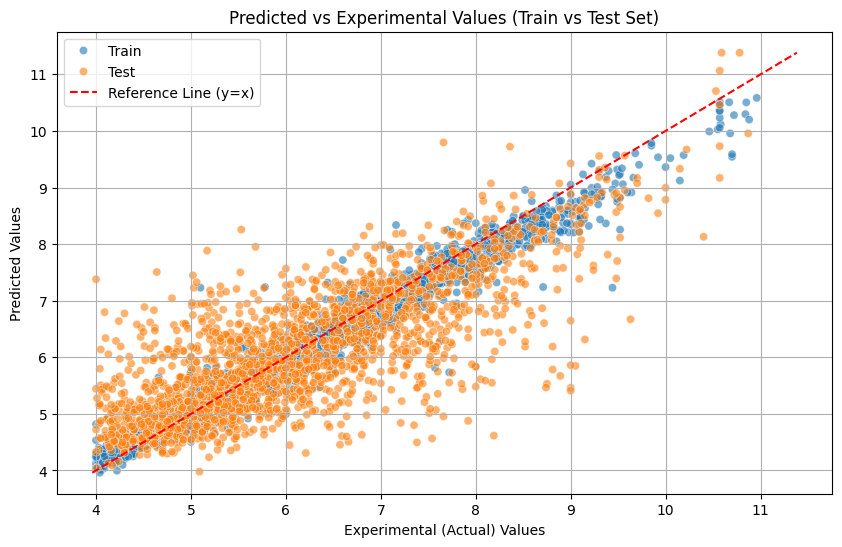

In [48]:
# Prepare training data for plotting
train_plot_df = pd.DataFrame({'Actual': df_preds['y_train'], 'Predicted': df_preds['yg'], 'Set': 'Train'})

# Prepare external test data for plotting
test_plot_df = pd.DataFrame({'Actual': predicted_test['y_test'], 'Predicted': predicted_test['yg_test'], 'Set': 'Test'})

# Combine the dataframes
combined_plot_df = pd.concat([train_plot_df, test_plot_df])

# Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=combined_plot_df, x='Actual', y='Predicted', hue='Set', alpha=0.6)

# Add a reference line (y=x)
max_val = max(combined_plot_df['Actual'].max(), combined_plot_df['Predicted'].max())
min_val = min(combined_plot_df['Actual'].min(), combined_plot_df['Predicted'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Reference Line (y=x)')


plt.xlabel("Experimental (Actual) Values")
plt.ylabel("Predicted Values")
plt.title("Predicted vs Experimental Values (Train vs Test Set)")
plt.legend()
plt.grid(True)
plt.show()

### Validación cruzada

In [49]:
# # Validación Cruzada

# # Configuración de LMO CV
# num_iterations = 5  # Número de iteraciones
# test_size = 14/49 # Porcentaje a dejar fuera (20%)
# #val_size = 2/49  # Porcentaje para validación dentro del train (10% del total)

# # # Hiperparámetros
# # learning_rate = 0.001
# # num_epochs = 200
# # batch_size = 40
# # patience = 10

# # Listas para almacenar métricas and all predictions/true values for plotting
# mse_scores = []
# r2_scores = []
# all_y_true = []
# all_y_pred = []


# for i in range(num_iterations):
#     print(f'Iteración LMO {i + 1}/{num_iterations}')

#     # Fijar semilla para cada iteración (para splits reproducibles)
#     set_seed(42 + i)  # Cambiar semilla por iteración para variabilidad controlada

#     # Split aleatorio en train+val y test
#     # Use df_x.values and df_y for splitting

#     # @title
#     # dividimos train test con stratified
#     discretizer_cv = sklearn.preprocessing.KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="uniform")
#     splitter_cv = StratifiedShuffleSplit(n_splits=N_SPLITS, test_size=test_size, random_state=None)
#     df_data_cv = df_data.copy()
#     y_discrete_cv = discretizer_cv.fit_transform(df_y.values.reshape(-1, 1))
#     split, split_test = next(splitter_cv.split(df_x.values, y_discrete_cv))
#     fractions_cv = ["train" if i in split else "test" for i in range(df_data_cv.shape[0])]
#     df_data_cv = df_data_cv.assign(fraction_cv=fractions_cv)
#     # df_d = df_d.assign(fraction=fractions)

#     # sacamos los vectores (x, y) de interés
#     x_train = df_x[df_data_cv["fraction"] == "train"].values
#     y_train = df_y[df_data_cv["fraction"] == "train"].values
#     x_test_iter = df_x[df_data_cv["fraction"] == "test"].values
#     y_test_iter = df_y[df_data_cv["fraction"] == "test"].values
#     y_train = np.reshape(y_train, -1)
#     y_test = np.reshape(y_test, -1)



#     # X_temp, X_test_iter, y_temp, y_test_iter = train_test_split(df_x.values, df_y.values, test_size=test_size, random_state=42 + i) # Explicitly use random_state


#     #X_train_iter, X_val_iter, y_train_iter, y_val_iter = train_test_split(x_train, y_train, test_size=val_size, random_state=42 + i) # Explicitly use random_state


#     # Apply the pipeline to the data splits
#     #x_train_iter_transformed = pipeline.transform(X_train_iter)
#     #X_val_iter_transformed = pipeline.transform(X_val_iter)
#     #x_test_iter_transformed = pipeline.transform(x_test_iter)

#     # Convert NumPy arrays to PyTorch tensors
#     x_train_iter_tensor = torch.FloatTensor(x_train)
#     y_train_iter_tensor = torch.FloatTensor(y_train).reshape(-1, 1)
#     # X_val_iter_tensor = torch.FloatTensor(X_val_iter_transformed)
#     # y_val_iter_tensor = torch.FloatTensor(y_val_iter).reshape(-1, 1)
#     x_test_iter_tensor = torch.FloatTensor(x_test_iter)
#     y_test_iter_tensor = torch.FloatTensor(y_test_iter).reshape(-1, 1)

#     # Create DataLoaders for the current iteration's data
#     train_dataset = TensorDataset(x_train_iter_tensor, y_train_iter_tensor)
#     train_loader_iter = DataLoader(train_dataset, batch_size=batch_size, shuffle=True) # Use local loader
#     # val_dataset = TensorDataset(X_val_iter_tensor, y_val_iter_tensor)
#     # val_loader_iter = DataLoader(val_dataset, batch_size=batch_size) # Use local loader


#     # Inicializar modelo, criterio, optimizador y early stopping
#     model = RegressionNet(input_size)
#     criterion = nn.MSELoss()
#     optimizer = optim.Adam(model.parameters(), lr=learning_rate)
#     # early_stopping = EarlyStopping(patience=patience, delta=0.001)

#     # Training loop (adapted to use the local loaders)
#     model.train()
#     for epoch in range(num_epochs):
#         epoch_train_loss = 0
#         for X_batch, y_batch in train_loader_iter: # Use local loader
#             optimizer.zero_grad()
#             outputs = model(X_batch)
#             loss = criterion(outputs, y_batch)
#             loss.backward()
#             optimizer.step()
#             epoch_train_loss += loss.item() * X_batch.size(0)
#         epoch_train_loss /= len(train_loader_iter.dataset) # Use local loader

#     # Evaluación en el conjunto left-out (test_iter)
#     model.eval()
#     with torch.no_grad():
#         y_pred_iter = model(x_test_iter_tensor).numpy()
#         y_true_iter = y_test_iter_tensor.numpy() # Use the tensor here

#     mse = mean_squared_error(y_true_iter, y_pred_iter) # Use y_true_iter and y_pred_iter for metrics
#     r2 = r2_score(y_true_iter, y_pred_iter) # Use y_true_iter and y_pred_iter for metrics
#     mse_scores.append(mse)
#     r2_scores.append(r2)
#     print(f'Iteración {i + 1} - MSE: {mse:.4f}, R²: {r2:.4f}')

#     all_y_true.extend(y_true_iter.flatten())
#     all_y_pred.extend(y_pred_iter.flatten())


# # Create a DataFrame for plotting
# cv_results_df = pd.DataFrame({'Actual': all_y_true, 'Predicted': all_y_pred})

# # Create the scatter plot
# plt.figure(figsize=(10, 6))
# sns.scatterplot(x='Actual', y='Predicted', data=cv_results_df)

# # Add a reference line (y=x)
# plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Reference Line (y=x)')

# # Add a simple linear regression line
# sns.regplot(x='Actual', y='Predicted', data=cv_results_df, scatter=False, color='green', label='Linear Regression Line')

# # Calculate and add the overall R-squared for CV predictions
# # Fix the f-string syntax here
# plt.text(min_val + (max_val - min_val) * 0.05, max_val - (max_val - min_val) * 0.1, f'R²cv = {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.2f}', fontsize=12, color='blue')

# # Resumen de LMO CV
# print(f'\nResultados de validación cruzada LMO ({num_iterations} iteraciones, leave {int(test_size*100)}% out):')
# print(f'MSE promedio: {np.mean(mse_scores):.4f} ± {np.std(mse_scores):.4f}')
# print(f'R² promedio: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}')
# plt.xlabel("Actual Values")
# plt.ylabel("Predicted Values")
# plt.title("Actual vs. Predicted Values (Cross-Validation)")
# plt.legend()
# plt.grid(True)
# plt.show()

In [50]:
# # Prepare training data for plotting
# train_plot_df = pd.DataFrame({
#     'Actual': df_preds['y_train'],
#     'Predicted': df_preds['yg'],
#     'Set': 'Train'
# })

# # Prepare cross-validation data for plotting
# cv_plot_df = pd.DataFrame({
#     'Actual': cv_results_df['Actual'],
#     'Predicted': cv_results_df['Predicted'],
#     'Set': 'Cross-Validation'
# })

# # Combine the dataframes
# combined_plot_df = pd.concat([train_plot_df, cv_plot_df])

# # Create the scatter plot
# plt.figure(figsize=(10, 6))
# sns.scatterplot(data=combined_plot_df, x='Actual', y='Predicted', hue='Set', alpha=0.6)

# # Add a reference line (y=x)
# # max_val = max(combined_plot_df['Actual'].max(), combined_plot_df['Predicted'].max())
# # min_val = min(combined_plot_df['Actual'].min(), combined_plot_df['Predicted'].min())
# plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Reference Line (y=x)')


# plt.xlabel("Experimental (Actual) Values")
# plt.ylabel("Predicted Values")
# plt.title("Predicted vs Experimental Values (Train vs Cross-Validation)")
# plt.legend()
# plt.grid(True)
# plt.show()

# # , H~2~O

#Resultados

In [51]:
# Create a dictionary to store the metrics
metrics_data = {
    'Metric': ['R2','MSE'],
    'Goodness of Fit (Train)': [r2_l, mean_squared_error(df_preds['y_train'], df_preds['yg'])], # Assuming 'r2' here is the R2 for goodness of fit
  #  'Cross-Validation (LMO) - Mean': [ np.mean(r2_scores), np.mean(mse_scores)],
    'External Validation (Test)': [r2_test, mse_test]}

# Create a pandas DataFrame from the dictionary
metrics_df = pd.DataFrame(metrics_data)
# Display the DataFrame
display(metrics_df.round(3))

,Metric,Goodness of Fit (Train),External Validation (Test)
0,R2,0.966,0.601
1,MSE,0.058,0.681


# Dominio de aplicación

In [52]:
# Define el dominio de aplicación utilizando el método del apalancamiento (leverage)
# Calcular la matriz de diseño para los datos de entrenamiento (estandarizados)
# Se añade una columna de unos para el término de intercepción
X_train_with_intercept = np.insert(x_train.numpy(), 0, 1, axis=1)

# Calcular la matriz Hat (o matriz de proyección) para los datos de entrenamiento
# H = X(X^T X)^-1 X^T
# El cálculo directo de la inversa puede ser numéricamente inestable,
# por lo que se usa np.linalg.pinv (pseudoinversa de Moore-Penrose)
hat_matrix = X_train_with_intercept @ np.linalg.pinv(X_train_with_intercept.T @ X_train_with_intercept)

# Calcular el umbral de apalancamiento. Un umbral común es 3 * (p + 1) / n,
# donde p es el número de predictores y n es el número de observaciones de entrenamiento.
p = x_train.shape[1]  # Número de predictores (características)
n = x_train.shape[0]  # Número de observaciones de entrenamiento
leverage_threshold = 3 * (p + 1) / n

leverages = []
XTX_inv = np.linalg.pinv(X_train_with_intercept.T @ X_train_with_intercept)

print(f"Umbral de apalancamiento: {leverage_threshold:.4f}")
# # Calcula las residuales
df_preds['Residuals'] = df_preds['y_train'] - df_preds['yg']
predicted_test['Residuals'] = predicted_test['y_test'] - predicted_test['yg_test']
#Agregamos la información
predicted_test_ = pd.concat([x_test_.reset_index(), predicted_test], axis = 1)
df_preds_ = pd.concat([x_train_.reset_index(), df_preds], axis = 1)

Umbral de apalancamiento: 0.3664


In [53]:
# Calculate leverage for the training set
# Assuming X_train_with_intercept and XTX_inv are available from previous cells
train_leverages = np.diag(X_train_with_intercept @ XTX_inv @ X_train_with_intercept.T)
df_preds_['Leverage'] = train_leverages

# Calculate leverage for the test set
x_test_with_intercept = np.insert(x_test, 0, 1, axis=1)
test_leverages = []
for i in range(x_test_with_intercept.shape[0]):
    x_i_test = x_test_with_intercept[i, :].reshape(-1, 1)
    # Explicitly cast the result to a float to avoid the DeprecationWarning
    leverage_test = float((x_i_test.T @ XTX_inv @ x_i_test)[0, 0])
    test_leverages.append(leverage_test)
predicted_test_['Leverage'] = test_leverages


/tmp/ipykernel_1372/2145348593.py:12: DeprecationWarning:

__array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)



In [54]:
# Combine the subsets by rows
combined_df = pd.concat([df_preds_, predicted_test_], ignore_index=True)

# 1. Calcular la media y desviación estándar
columna = 'Residuals' # Vamos a estandarizar 'edad' esta vez
media = combined_df[columna].mean()
desviacion = combined_df[columna].std()

# 2. Aplicar la fórmula Z-score
combined_df['STD_residuals'] = (combined_df[columna] - media) / desviacion

In [55]:
activity_limit= 9
# Creamos uan gráfica de valores predichos respecto al Dominio de Aplicación
fig = px.scatter(combined_df, x="Leverage", y="Residuals",
                 title="Williams plot DA",
                 color = 'fraction',
                 width= 900,height = 500)

#___________Respecto a la linea_________________________________________________

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color)


#____Formateo_____________________________________________________________________
# Set background color to white
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#fig.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
fig.update_layout(hoverlabel_font_size=20)
#fig.update_layout(showlegend=False) # This line removes the legend
#fig.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=6)) # Increase marker size
#____respecto a linea_____________________________________________________________
fig.add_vline(x=leverage_threshold, line_width=3, line_color="green")
fig.add_hline(y=2, line_width=1, line_dash="dash", line_color="green")
fig.add_hline(y=0, line_width=1, line_color="black")
fig.add_hline(y=-2, line_width=1, line_dash="dash", line_color="green")
#_______________________________________________________________________________
#___________Respecto al formato_________________________________________________
fig1 = molplotly.add_molecules(fig=fig,
                                     df=combined_df,
                                     smiles_col='SMILES',
                                     color_col='fraction',
                                     caption_cols=['Activity', 'Molecule ChEMBL ID'],
                                     fontsize=15,
                                     width=220)
fig1.run(port=8064)

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

In [56]:
activity_limit= 9
# Creamos uan gráfica de valores predichos respecto al Dominio de Aplicación
fig = px.scatter(combined_df, x="Leverage", y="STD_residuals",
                 title="Williams plot DA",
                 color = 'fraction',
                 width= 900,height = 500)

#___________Respecto a la linea_________________________________________________

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color)


#____Formateo_____________________________________________________________________
# Set background color to white
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#fig.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
fig.update_layout(hoverlabel_font_size=20)
#fig.update_layout(showlegend=False) # This line removes the legend
#fig.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=6)) # Increase marker size
#____respecto a linea_____________________________________________________________
fig.add_vline(x=leverage_threshold, line_width=3, line_color="green")
fig.add_hline(y=2, line_width=1, line_dash="dash", line_color="green")
fig.add_hline(y=0, line_width=1, line_color="black")
fig.add_hline(y=-2, line_width=1, line_dash="dash", line_color="green")
#_______________________________________________________________________________
#___________Respecto al formato_________________________________________________
fig1 = molplotly.add_molecules(fig=fig,
                                     df=combined_df,
                                     smiles_col='SMILES',
                                     color_col='fraction',
                                     caption_cols=['Activity', 'Molecule ChEMBL ID'],
                                     fontsize=15,
                                     width=220)
fig1.run(port=8064)

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

# EXPLORACIÓN

Evaluación final con las nuevas mols

## Descriptores, predicción y modelos DA

In [57]:
# mordred_descriptors = All_Mordred_descriptors(xplor_co['SMILES'])
# Reset the index of xplor_co to ensure unique indices before concatenation
# xplor_co_reset = xplor.reset_index(drop=True)
xplor_mordred = pd.concat([xplor, df_embeddings_xplor], axis=1)

In [58]:
xplor_mordred.tail()

,Cmpd,SMILES,G,0,1,2,3,4,5,6,...,374,375,376,377,378,379,380,381,382,383
1439,RA-1438,O=C1C2=CC(OC)=C(OCCCOCC3=CC([N+]([O-])=O)=CC=C...,xplor,0.254875,-0.091344,0.020622,0.173651,-0.023935,-0.021491,-0.141469,...,0.023922,-0.098178,0.056407,0.209503,0.143968,-0.173085,-0.023309,0.043867,0.064698,0.048127
1440,RA-1439,O=C1C2=CC(OC)=C(OCCCOCC3=C([N+]([O-])=O)C=CC=C...,xplor,0.098794,-0.007572,-0.014645,0.076868,-0.058077,0.001206,-0.017135,...,-0.100574,-0.018792,0.067499,-0.152433,0.103412,-0.129858,-0.037760,0.097921,-0.112588,-0.096919
1441,RA-1440,O=C1C2=CC(OC)=C(OCCCOCC3=CC=C([N+]([O-])=O)C=C...,xplor,0.169901,0.087560,-0.141364,0.103867,0.043232,-0.082941,0.008691,...,-0.042088,-0.002095,-0.016877,-0.055031,0.140737,-0.132026,-0.057785,0.162725,-0.092887,-0.038729
1442,penicilna G,CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)CC3=CC...,comercial,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1443,oxaciline,CC1=C(C(=NO1)C2=CC=CC=C2)C(=O)N[C@H]3[C@@H]4N(...,comercial,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [59]:
df_val = xplor_mordred[df_x.columns] #Esta variable entra al pipeline
df_val = df_val.dropna()# Quita las filas que tienen NaN elementos

In [60]:
# # Convert the DataFrame values to a PyTorch tensor
# # df_val_tensor = torch.FloatTensor(df_val).numpy()
# x_val = df_val.values
# x_val = x_val.astype(float)
# val_tensor = torch.from_numpy(x_val).float()


# with torch.no_grad():
#     # Use the trained regression_model for prediction
#     preds = model(val_tensor).numpy()

# # Create a new DataFrame to store the predictions
# xplor_mordred['Predicted_Activity'] = preds
# display(xplor_mordred['Predicted_Activity'])

In [61]:
import numpy as np

# Convert the DataFrame values to a PyTorch tensor
x_val = df_val.values
x_val = x_val.astype(float)
val_tensor = torch.from_numpy(x_val).float()


with torch.no_grad():
    # Use the trained regression_model for prediction
    preds = model(val_tensor).numpy()

# Create a new DataFrame to store the predictions
# Initialize the 'Predicted_Activity' column with NaN for all rows in xplor_mordred
xplor_mordred['Predicted_Activity'] = np.nan

# Assign the predictions to the correct rows using the index of df_val
xplor_mordred.loc[df_val.index, 'Predicted_Activity'] = preds.flatten()

display(xplor_mordred['Predicted_Activity'])

,Predicted_Activity
0,4.775023
1,4.696819
2,4.775023
3,4.870420
4,4.801298
...,...
1439,4.342916
1440,4.446388
1441,4.497764
1442,NaN


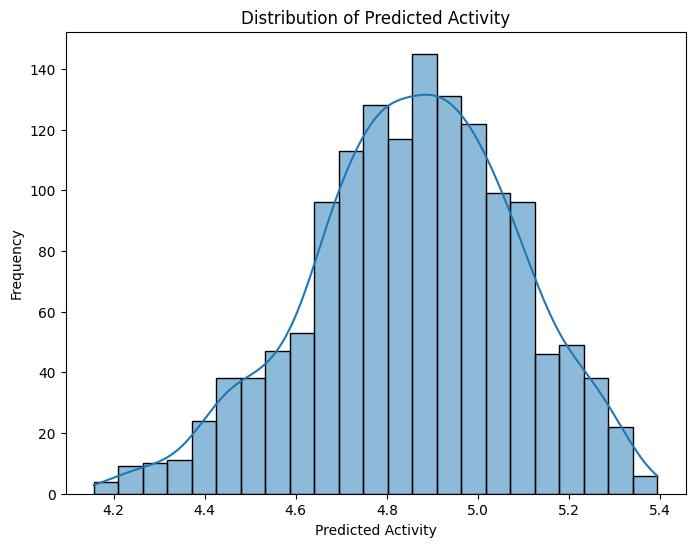

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a histogram of the 'Predicted_Activity' column
plt.figure(figsize=(8, 6))
sns.histplot(data=xplor_mordred, x='Predicted_Activity', kde=True)
plt.title('Distribution of Predicted Activity')
plt.xlabel('Predicted Activity')
plt.ylabel('Frequency')
plt.show()

# Predicciones

In [63]:
# # Calcular la matriz de diseño para los nuevos casos (estandarizados)
# # Se añade una columna de unos para el término de intercepción
# new_cases_scaled_with_intercept = np.insert(x_val, 0, 1, axis=1)

# # Calcular el apalancamiento (leverage) para cada nuevo caso
# # h_ii = x_i^T (X^T X)^-1 x_i
# # Donde x_i es el vector de características del nuevo caso
# leverages = []
# XTX_inv = np.linalg.pinv(X_train_with_intercept.T @ X_train_with_intercept)
# for i in range(new_cases_scaled_with_intercept.shape[0]):
#     x_i = new_cases_scaled_with_intercept[i, :].reshape(-1, 1)
#     leverage = x_i.T @ XTX_inv @ x_i
#     leverages.append(leverage[0,0])

# xplor_mordred['Leverage'] = leverages

# # Determinar si cada nuevo caso está dentro o fuera del dominio de aplicación
# xplor_mordred['Within_Application_Domain'] = xplor_mordred['Leverage'] < leverage_threshold

# # Mostrar los nuevos casos con su apalancamiento y si están dentro del dominio
# # display(xplor_mordred[[ 'Leverage', 'Within_Application_Domain']])

In [64]:
# Calcular la matriz de diseño para los nuevos casos (estandarizados)
# Se añade una columna de unos para el término de intercepción
new_cases_scaled_with_intercept = np.insert(x_val, 0, 1, axis=1)

# Calcular el apalancamiento (leverage) para cada nuevo caso
# h_ii = x_i^T (X^T X)^-1 x_i
# Donde x_i es el vector de características del nuevo caso
leverages = []
XTX_inv = np.linalg.pinv(X_train_with_intercept.T @ X_train_with_intercept)
for i in range(new_cases_scaled_with_intercept.shape[0]):
    x_i = new_cases_scaled_with_intercept[i, :].reshape(-1, 1)
    leverage = x_i.T @ XTX_inv @ x_i
    leverages.append(leverage[0,0])

# Initialize 'Leverage' column with NaN for all rows in xplor_mordred
xplor_mordred['Leverage'] = np.nan

# Assign the calculated leverages to the correct rows using the index of df_val
xplor_mordred.loc[df_val.index, 'Leverage'] = leverages

# Determinar si cada nuevo caso está dentro o fuera del dominio de aplicación
xplor_mordred['Within_Application_Domain'] = xplor_mordred['Leverage'] < leverage_threshold

# Mostrar los nuevos casos con su apalancamiento y si están dentro del dominio
# display(xplor_mordred[[ 'Leverage', 'Within_Application_Domain']])

In [65]:
activity_limit= 5.3
# Creamos uan gráfica de valores predichos respecto al Dominio de Aplicación
fig = px.scatter(xplor_mordred, x="Leverage", y="Predicted_Activity",
                 title="LeverageMethod_domain vs pred",
                 hover_name="Cmpd",
                 width= 900,height = 500)

#___________Respecto a la linea_________________________________________________
fig.add_vline(x=leverage_threshold, line_width=3, line_color="green")
fig.add_hline(y=activity_limit, line_width=1, line_color="green")
fig.update_traces(marker=dict(size=3)) # Increase marker size
fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color)
#___________Respecto al formato_________________________________________________
fig2 = molplotly.add_molecules(fig=fig,
                                     df=xplor_mordred,
                                     smiles_col='SMILES',
                                     #color_col='fraction',
                                     caption_cols=['Cmpd'],
                                     fontsize=15,
                                     width=220)
fig2.run(port=8765)

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>